# Imaging, part 2: regularized maximum likelihood

Part 1 simulated AMI data of a lopsided ring of dust next to a star. This part reconstructs the ring from those data using **regularized maximum likelihood** (RML).

An image has far more pixels than an interferometer has independent measurements, so many images fit the data equally well. RML picks one by minimizing

$$\mathcal{L}(\text{image}) = \tfrac{1}{2}\chi^2(\text{image}) + w\,R(\text{image}),$$

where χ² measures the misfit to the data and R is a **regularizer**, a penalty that prefers some images over others. We use maximum entropy, which prefers smooth, positive images close to a flat default. The weight w sets the balance: too small and the image fits the noise, too large and it is smoothed into whatever the regularizer prefers.

The steps are:
1. look at the dirty image and the beam, to see what the data can resolve;
2. build a starting image, either from a parametric fit (moments) or from the dirty image;
3. fit once at a fixed weight;
4. sweep the weight with an L-curve, and choose it by the discrepancy principle;
5. check the result.

In [1]:
import sys
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpyro.distributions as dist

repo_root = Path.cwd()
if not (repo_root / "src").exists():
    repo_root = repo_root.parent
if str(repo_root / "src") not in sys.path:
    sys.path.insert(0, str(repo_root / "src"))

from virgil.coverage import ami_grid_record
from virgil.fitting import fit
from virgil.imaging import (
    MaxEntropy,
    beam,
    diagnose,
    dirty_image,
    field_of_view,
    image_priors,
    l_curve,
    nyquist_pixel_scale,
    starting_image,
)
from virgil.models import Image, PointSource, System
from virgil.oidata import OIData
from virgil.plotting import plot_model, plot_residual_map
from virgil.scenes import ring

# The scene of part 1: a lopsided ring with 5% of the flux, next to a star.
template = OIData(ami_grid_record(wavelength_m=4.8e-6, rotation_deg=-6.9))
npix, pixel_scale = 64, 20.0
fov = npix * pixel_scale
truth_image = ring(npix, pixel_scale, radius_mas=240.0, width_mas=36.0, inc_deg=50.0, pa_deg=30.0, asymmetry=0.6, asymmetry_pa_deg=90.0)
truth = System(star=PointSource(), dust=Image.from_brightness(truth_image, pixel_scale, flux=0.05))
data = template.with_model(truth, key=jax.random.PRNGKey(1))

resolution = beam(data)
print(f"{data.vis.size} data (DISCO coefficients)")
print(f"beam {resolution.major_mas:.0f} × {resolution.minor_mas:.0f} mas; Nyquist pixel {nyquist_pixel_scale(data):.0f} mas; interferometric field of view {field_of_view(data, largest_mas=float('inf')):.0f} mas")

588 data (DISCO coefficients)
beam 154 × 131 mas; Nyquist pixel 84 mas; interferometric field of view 3300 mas


## The dirty image and the beam

The simplest image is the **dirty image**, the inverse Fourier transform of the data with every unmeasured frequency set to zero. virgil's `dirty_image` computes it by least squares from the data's uv samples. Passing the star's flux ratio (`flux_ratio`) removes the star, leaving only the extended emission.

The dirty image is the truth convolved with the **dirty beam**, the response to a point source. The beam's core sets the resolution; `beam(data)` approximates it by an ellipse, and its FWHM is shaded in the lower-left corner of every reconstructed image. The dirty image shows the ring but is not the answer: it is blurred by the beam, and its sidelobes add negative and spurious structure. A star 20 times brighter than the ring also amplifies any small error in the data's normalization, so `dirty_image` subtracts the best-fitting point source rather than a fixed one.

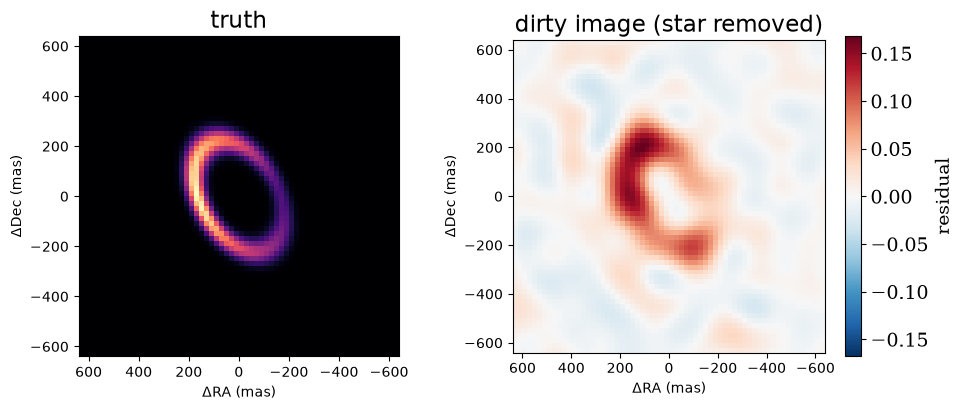

In [2]:
dirty = dirty_image(data, npix, pixel_scale, flux_ratio=0.05)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
plot_model(truth.dust, fov_mas=fov, npix=npix, ax=axes[0], title="truth")
plot_residual_map(dirty, fov, ax=axes[1], title="dirty image (star removed)")
plt.tight_layout()
plt.show()

## Starting images

The fit needs a starting image, and `starting_image` builds one from the data:
- **A parametric fit.** It fits a star plus a circular Gaussian envelope, and uses the envelope's flux and width.
- **A pixel grid.** The pixel scale is a quarter of the Nyquist pixel, and the field of view spans six envelope widths (and at least four resolution elements), but no more than the interferometric field of view (here capped at the truth's field).
- **A hole under the star.** `hole_mas` cuts a hole of half a beam in the image's support there. Extended flux that close to the star is nearly indistinguishable from the star's own light, so without a hole the fit can trade one against the other.
- **The starting pixels.** `start="moments"` takes them from the fitted Gaussian. `start="dirty"` takes the positive part of the dirty image, which already has the right shape when the coverage is good, as it is here.
- **The grid's frame.** `rotation_deg="grid"` turns the pixel grid to the data's uv lattice (here −6.9°), which gives the exact fast matrix Fourier transform of part 1. The pixels then lie in the lattice frame, not North up; `plot_model` and the metrics render them North up.

- **Padding.** `pad_to_mas` pads the grid with empty pixels, centred, out to at least that width, at the same pixel scale. It may exceed the interferometric field λ / B_min, where the data do not constrain the flux, so pair a large field with a support or priors. Unlike `EnsembleSpec.field_mas`, it never shrinks the grid.

A star and an `Image` together make a `System`. The analytic star also fixes the image's position, which the closure phases alone cannot.

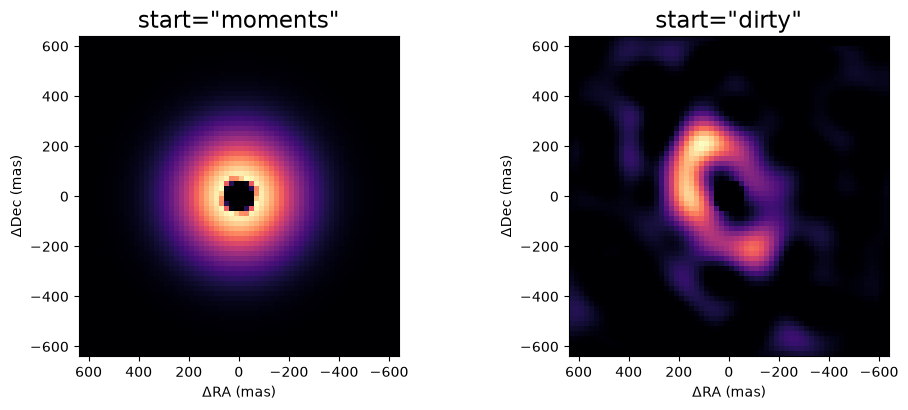

In [3]:
starts = {kind: starting_image(data, largest_mas=fov, start=kind, hole_mas=0.5 * resolution.minor_mas, rotation_deg="grid") for kind in ("moments", "dirty")}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (kind, start) in zip(axes, starts.items()):
    plot_model(start.env, fov_mas=fov, npix=npix, ax=ax, title=f'start="{kind}"')
plt.tight_layout()
plt.show()

## One regularized fit

`fit` minimizes the loss above:
- Its free parameters are the keys of the priors dict. `image_priors` gives flat priors on the image's log-brightness, so only the data and the regularizer constrain the pixels.
- The brightness is the softmax of the log-brightness, so it stays positive and sums to one. The image's flux is a separate parameter and is fitted too.
- Maximum entropy has no least-squares form, so `fit` uses L-BFGS. It reports whether it converged, and runs in float64 by default.

Here is one fit, at w = 100.

In [4]:
start = starts["moments"]
priors = image_priors(start) | {"env.flux": dist.LogUniform(1e-3, 2.0)}
one = fit(start, priors, data, [MaxEntropy(100.0, path="env")])
print(f"converged {one.info['converged']} after {one.info['steps']} steps; chi2 per point {one.info['chi2_red']:.3f}; image flux {float(one.model.env.flux):.4f} (truth 0.05)")

converged True after 649 steps; chi2 per point 1.009; image flux 0.0514 (truth 0.05)


## Choosing the weight: the L-curve and the discrepancy principle

`l_curve` fits the image at a sequence of weights, from strong to weak, each fit starting from the previous one, and records χ² and the unweighted penalty R of each. Two criteria read a weight off the sweep:
- **The discrepancy principle** (`LCurve.discrepancy`) chooses the weight at which χ² per data point reaches one. That is how well the truth itself fits noisy data, so it regularizes as strongly as the data allow. It relies on correct error bars. Reaching χ² per point ≈ 1 this way is the target the weight is set to hit, not a test that the fit is good.
- **The corner** (`LCurve.corner`) is where the curve of log χ² against log R bends most sharply. It needs no error bars, but the corner of a coarse or noisy sweep is itself noisy.

Here both starting images are swept, and the two criteria are marked on each curve.

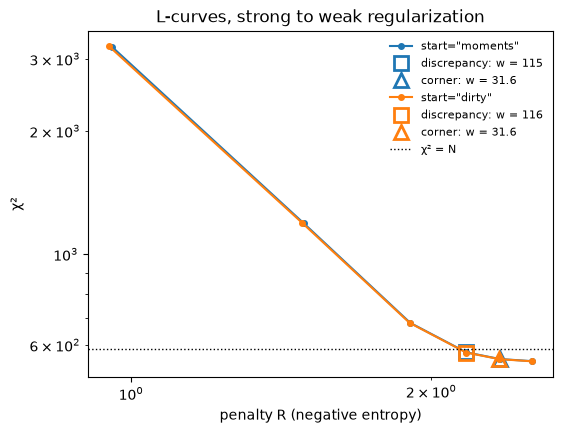

start="moments" converged at each weight: 3.16e+03: True, 1e+03: True, 316: True, 100: True, 31.6: True, 10: True
start="dirty" converged at each weight: 3.16e+03: True, 1e+03: True, 316: True, 100: True, 31.6: True, 10: True


In [5]:
weights = jnp.logspace(3.5, 1.0, 6)
curves = {kind: l_curve(s, image_priors(s) | {"env.flux": dist.LogUniform(1e-3, 2.0)}, data, MaxEntropy(1.0, path="env"), weights, max_steps=200_000) for kind, s in starts.items()}

fig, ax = plt.subplots(figsize=(6, 4.5))
for (kind, curve), colour in zip(curves.items(), ("C0", "C1")):
    ax.plot(curve.penalty, curve.chi2, "o-", color=colour, ms=4, label=f'start="{kind}"')
    for name, weight, marker in (("discrepancy", curve.discrepancy(), "s"), ("corner", curve.corner(), "^")):
        k = int(jnp.argmin(jnp.abs(jnp.log(curve.weights) - jnp.log(weight))))
        ax.plot(curve.penalty[k], curve.chi2[k], marker, color=colour, ms=10, mfc="none", mew=2, label=f"{name}: w = {weight:.3g}")
ax.axhline(data.vis.size, color="k", ls=":", lw=1, label="χ² = N")
ax.set(xscale="log", yscale="log", xlabel="penalty R (negative entropy)", ylabel="χ²", title="L-curves, strong to weak regularization")
ax.legend(frameon=False, fontsize=8)
plt.show()
for kind, curve in curves.items():
    print(f'start="{kind}" converged at each weight: ' + ", ".join(f"{float(w):.3g}: {r.info['converged']}" for w, r in zip(curve.weights, curve.results)))

## Too much, about right, too little

A good weight sits in a range, not at a point. Here are three fits from the moments sweep: a decade more regularized than the discrepancy weight, at it, and a decade less. Too much regularization blurs the ring into a smooth halo; too little lets the image fit the noise, and it breaks into speckles.

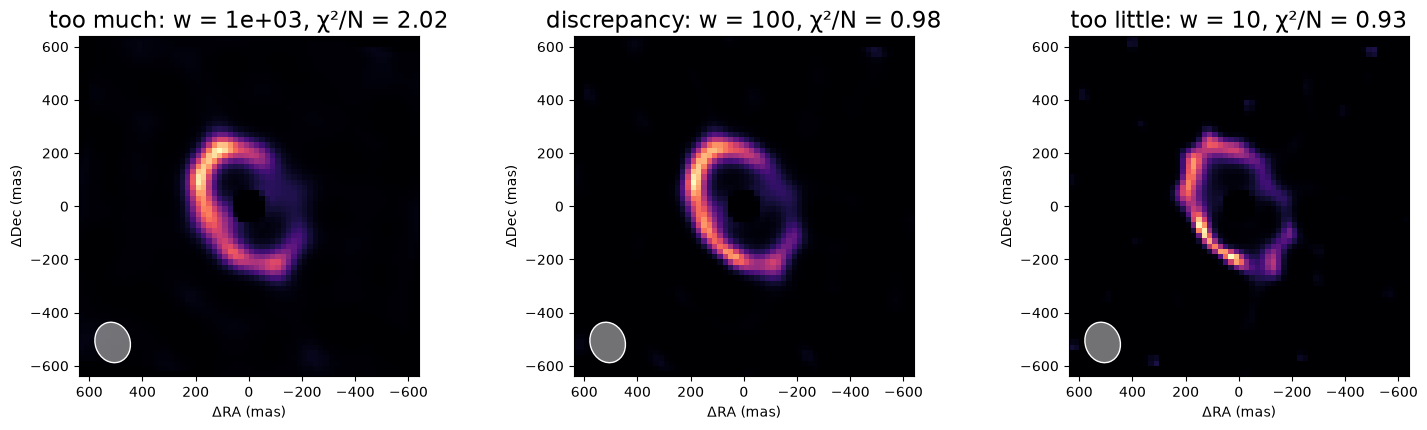

In [6]:
curve = curves["moments"]
chosen = curve.discrepancy()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, factor, label in zip(axes, (10.0, 1.0, 0.1), ("too much", "discrepancy", "too little")):
    k = int(jnp.argmin(jnp.abs(jnp.log(curve.weights) - jnp.log(factor * chosen))))
    r = curve.results[k]
    plot_model(r.model.env, fov_mas=fov, npix=npix, ax=ax, title=f"{label}: w = {float(curve.weights[k]):.3g}, χ²/N = {r.info['chi2_red']:.2f}", beam=resolution)
plt.tight_layout()
plt.show()

## The result, and the two starting images

Each sweep's fit nearest its discrepancy weight is shown with the beam shaded, and below it the signed difference from the truth. These are maximum a posteriori images with no uncertainties, so the residuals are not z-scores. The two starting images converge to nearly the same reconstruction, a good sign that the fit has found the optimum rather than stopping near its start.

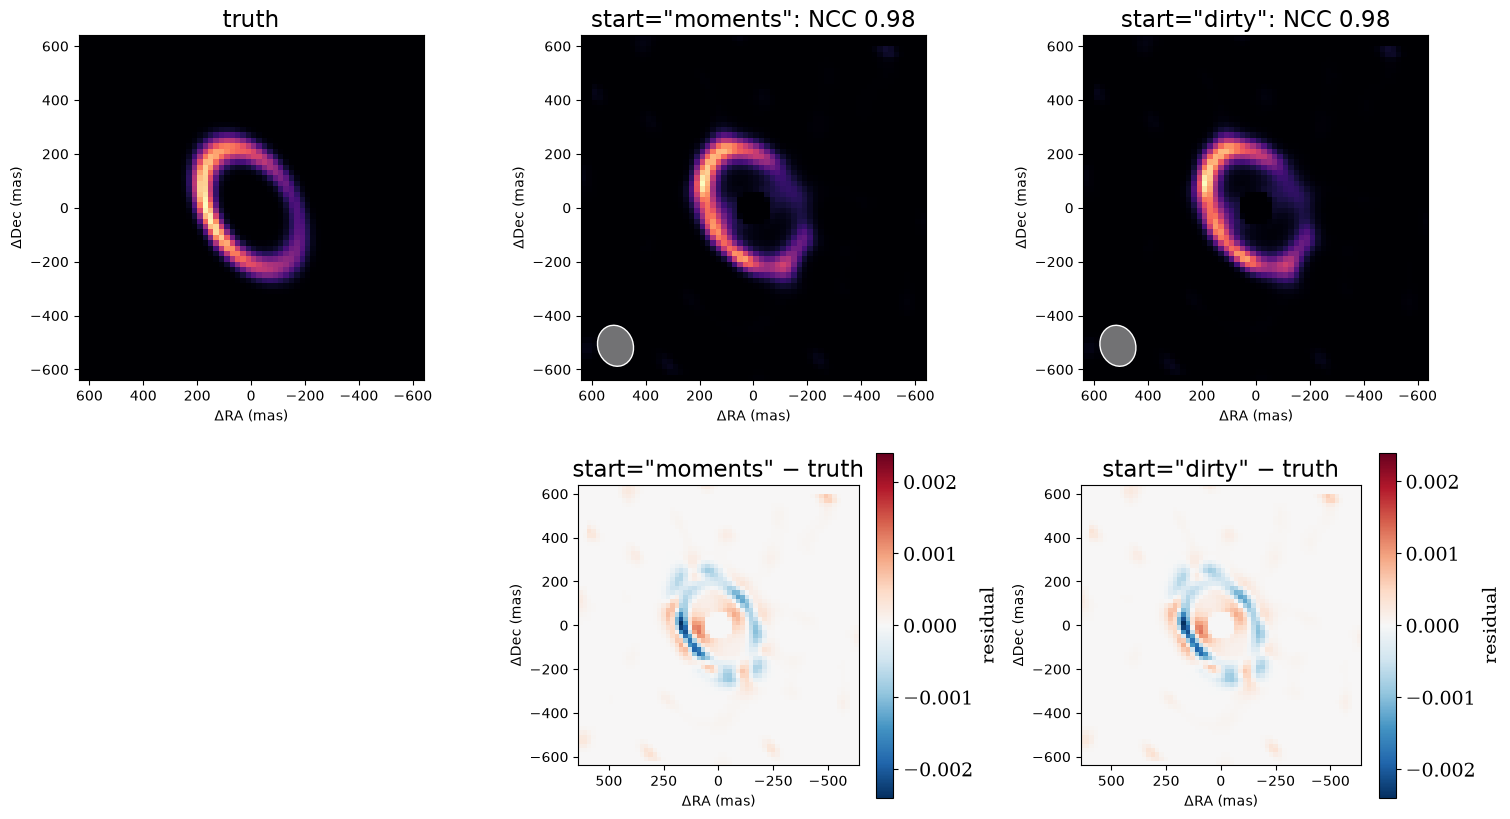

In [7]:
def ncc(a, b):
    a, b = a - a.mean(), b - b.mean()
    return float(jnp.sum(a * b) / jnp.sqrt(jnp.sum(a * a) * jnp.sum(b * b)))


fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
plot_model(truth.dust, fov_mas=fov, npix=npix, ax=axes[0, 0], title="truth")
axes[1, 0].axis("off")
final = {}
for column, (kind, curve) in enumerate(curves.items(), start=1):
    k = int(jnp.argmin(jnp.abs(jnp.log(curve.weights) - jnp.log(curve.discrepancy()))))
    final[kind] = curve.results[k].model
    image = final[kind].env.render(npix, fov)
    plot_model(final[kind].env, fov_mas=fov, npix=npix, ax=axes[0, column], title=f'start="{kind}": NCC {ncc(image, truth_image):.2f}', beam=resolution)
    plot_residual_map(image - truth_image, fov_mas=fov, ax=axes[1, column], title=f'start="{kind}" − truth')
plt.tight_layout()
plt.show()

## Checking the result

`diagnose` checks a reconstruction for common problems and warns when a check fails:
- χ² per point for each dataset;
- whether something anchors the image's position, here the star;
- the pixel scale against the Nyquist pixel;
- flux at the edge of the field, a sign that the field is too small;
- the image's centroid;
- how much worse χ² gets when the image is turned by 180°. A large value means the closure phases fix the orientation.

In [8]:
print(diagnose(final["moments"], data))

chi2_red                [0.979]
chi2_red_by_observable  [{'vis': 0.9785587396187714}]
short_baseline_mean     None
anchored                True
pixel_scale_mas         [20.9]
edge_flux               [0.0197]
centroid_mas            [[50.3, 17.9]]
flip_dchi2              2.11e+04
phase_regime            [0]

No warnings.


## Pixel types and regularizers

The softmax image of the fits above keeps the brightness positive and the flux separate, but it can never reach exactly zero. Two other pixel types suit particular regularizers. Both are a [`LinearImage`][virgil.models.LinearImage], whose total flux is the sum of its pixels (there is no separate flux to fit):
- **Maximum entropy: √I pixels** (`parametrization="sqrt"`). The fitted array is the square root of the flux, so the flux `x²` is positive without a bound, and entropy keeps its interior minimum. A gradient step in x moves I by −4I ∂J/∂I, the entropic mirror-descent preconditioner up to a factor of 4, which conditions the problem for the quasi-Newton solver.
- **TSV, TV and L1: bounded linear pixels** (`parametrization="linear"`) with `fit(..., method="lbfgsb")`. These penalties are minimized at exactly zero pixels, and in square-root coordinates a zero pixel is a flat, slow stationary point. L-BFGS-B takes non-negativity as a box bound on the pixels instead, so zeros are reached in finite steps.

The parametrization changes how the optimizer moves, not the problem: both minimize ½χ² + wR over non-negative fluxes, so the image at the optimum is the same.

Put a `LinearImage` in a `System` with a fixed-flux component (a star), or use maximum entropy: otherwise nothing stops TSV, TV or L1 from shrinking the flux to zero.

## A small worked example

A small simulated image on a coarse AMI grid (0.7 m pitch): a smooth Gaussian truth, with noise at the quoted error bars. The folded cell below is setup.

In [9]:
import warnings

import jax
import jax.numpy as jnp
import numpy as onp
import numpyro.distributions as dist

from virgil import CalibrationNuisance, ComplexVisData
from virgil.coverage import ami_grid_record
from virgil.fitting import fit, kkt_report
from virgil.imaging import MaxEntropy, image_priors, l_curve
from virgil.models import LinearImage
from virgil.oidata import OIData
from virgil.radio import fit_staged_nuisances


# The example runs in float64; it comes after every cell above, which are unaffected.
jax.config.update("jax_enable_x64", True)
warnings.filterwarnings("ignore", message=".*cannot see inside a function model.*")

n, scale, flux = 8, 30.0, 0.3
grid = (jnp.arange(n) - (n - 1) / 2) * scale
gx, gy = jnp.meshgrid(grid, grid)
shape = jnp.exp(-(gx**2 + gy**2) / (2 * 40.0**2))
shape = flux * shape / shape.sum()


def pixels(p, parametrization):
    return LinearImage(p, scale, parametrization=parametrization, reference_flux=flux)


small = OIData(ami_grid_record(pitch_m=0.7)).with_model(pixels(jnp.sqrt(shape), "sqrt"), key=jax.random.PRNGKey(3))
start = pixels(jnp.sqrt(jnp.full((n, n), flux / n**2)), "sqrt")
priors = image_priors(start)

### Choosing the weight

`LCurve.dof_discrepancy` refines the discrepancy principle. A fitted image absorbs some of the noise, so χ² falls to n − G, not n, with n the number of data and G the effective degrees of freedom the fit has used (estimated stochastically). The weight is the root of m(w) = χ²/s² − (n − G):
- **s² is the noise scale on the quoted errors, taken from the scatter of the data.** Measure it from repeated observations or calibrator scatter, never by fitting it with the image: a flexible image absorbs structure into s² and the root moves to a weight that is too weak. The default is 1, right here because the simulation's errors are as quoted.
- **No root is a failure.** If m never changes sign over the sweep, the weight is `None` and a warning is raised. The weak end of the sweep is never a fallback, because it is the least-regularized image: extend the sweep, or suspect the error bars.
- **The strongest crossing is the default.** m can cross zero more than once, and every crossing is in `roots`. The one at the largest weight is chosen: the smoothest image still consistent with the data.
- **The secant cap.** The root interpolated from the sweep is refitted, and up to `max_secant` further secant steps are taken (default 1) until |m| is within three standard errors of G. Otherwise `accepted` is false and a warning says so: raise `max_secant` or refine the sweep.

In [10]:
regularizer = MaxEntropy(1.0)
curve = l_curve(start, priors, small, regularizer, jnp.logspace(4, 2, 9), max_steps=3000)
choice = curve.dof_discrepancy(small, regularizer)
print(f"w = {choice.weight:.0f}, accepted {choice.accepted}, roots {[round(r) for r in choice.roots]}")
print(f"chi2 = {choice.chi2:.1f}, G = {choice.g:.1f} ± {choice.g_se:.1f}, n = {choice.n_real:.0f}, m = {choice.m:.2f}")

w = 4185, accepted True, roots [4185]
chi2 = 87.1, G = 19.5 ± 2.1, n = 109, m = -2.43


### Certifying convergence

A loss that has stopped falling is not a converged fit: the optimizer may have given up on a slope. `kkt_report` tests the optimality conditions directly:
- **Gradient conditions.** For √I and softmax pixels, the gradient per pixel flux, less its multiplier, is small on the lit pixels (`kkt_rel`, and `kkt_w` in units of w/F). For bounded linear pixels, the projected gradient is small (`pg_rel`) and no pixel at zero wants to grow (`zero_violation`). Active bounds are not violations.
- **`want_grow`.** The fraction of dark pixels whose objective would raise them: an unfinished fit.
- **`band_limit`.** For a lone maximum entropy, the power of ln b beyond the data's highest spatial frequency. It is about 1 at an optimum; larger means structure the data cannot constrain.
- **Nuisances.** The gradient of every other fitted parameter is reported too.

`converged` is true only when all of these pass (the nuisance gradients only when `start=` is passed). A two-step fit shows what failure looks like.

In [11]:
best = [MaxEntropy(choice.weight)]
short = fit(start, priors, small, best, init=curve.results[-1].values, max_steps=2)
done = fit(start, priors, small, best, init=curve.results[-1].values, max_steps=3000)
for name, result in (("2 steps", short), ("converged fit", done)):
    report = kkt_report(result, priors, small, best)
    image = report["images"]["."]
    print(f"{name}: converged {report['converged']}, kkt_rel {image['kkt_rel']:.1e}, band_limit {image['band_limit']:.2f}")

/tmp/ipykernel_2010730/857592970.py:2: RuntimeWarning: fit(method='lbfgs') did not converge in 2 steps, the step limit; raise max_steps.
  short = fit(start, priors, small, best, init=curve.results[-1].values, max_steps=2)


2 steps: converged False, kkt_rel 4.5e-01, band_limit 1.64
converged fit: converged True, kkt_rel 3.5e-07, band_limit 1.07


For TSV, TV or L1 the same call certifies a `method="lbfgsb"` fit of a `parametrization="linear"` image: fit with `[TSV(w, beam_mas=...)]`, then call `kkt_report` with the same arguments. Restart an unconverged fit from its own values with a tighter `gtol` and report again.

### Gains and offsets in stages

Radio data need antenna-based gains (and optionally offsets) fitted with the image. Fitting everything at once from a flat image can trade image structure for gain, so `fit_staged_nuisances` (in `virgil.radio`) follows Cornwell & Wilkinson's order:
1. the image, with the nuisances nominal;
2. the nuisances, with the image held fixed;
3. both jointly, followed by a `kkt_report` of the image.

Two guards come with it:
- **The reference gain.** Gains are relative: scaling every gain and the flux by the same factor leaves the data unchanged. One observation's gain is fixed at 1, by default the one with the largest Σw, so the flux scale comes from the best-measured data and not a lightly weighted observation.
- **The box-edge check.** L-BFGS-B fits each nuisance inside a box (gains default to 0.7–1.3). A nuisance that ends within 5% of the box width of an edge is probably being held there, not measured: `failed` is set and `edge` says which.

Here three observations have gains 1.1, 1.0 and 0.9, and unequal weights. The gains are recovered, but the image block of this short run is not yet certified: `fit` warns that it ran out of steps, and `kkt_report` agrees. Raise `max_steps` before trusting the image.

In [12]:
rng = onp.random.default_rng(0)
npts = 450
radius = 0.4 / (2 * (onp.pi / (180 * 3600e3)) * scale) * onp.sqrt(rng.uniform(0.05, 1, npts))
angle = rng.uniform(0, 2 * onp.pi, npts)
u, v = radius * onp.cos(angle), radius * onp.sin(angle)
obs = onp.repeat(onp.arange(3), 150)
weight = onp.repeat([0.2e6, 3e6, 1e6], 150)
nominal = ComplexVisData.from_arrays(u, v, onp.ones(npts) + 0j, weight, onp.full(npts, 230e9), obs=obs)
fixed = CalibrationNuisance(nominal, gains=False, offsets=False, alpha=False, sigmas=False, fit_flux=False)


def scene(values):
    return LinearImage(values["pixels"], scale, ft="dft", parametrization="sqrt", reference_flux=1.0)


truth = {"pixels": jnp.sqrt(shape / shape.sum())}
model = onp.asarray(nominal.model(scene(truth), truth, fixed))
gains = onp.array([1.1, 1.0, 0.9])[obs]
vis = gains * model + 1e-3 * (rng.normal(size=npts) + 1j * rng.normal(size=npts))
radio = ComplexVisData.from_arrays(u, v, vis, weight, onp.full(npts, 230e9), obs=obs)

In [13]:
flat = dist.ImproperUniform(dist.constraints.real, (), event_shape=(n, n))
staged = fit_staged_nuisances(
    radio,
    scene,
    {"pixels": flat},
    [MaxEntropy(1.0)],
    init={"pixels": jnp.full((n, n), 1 / n)},
    nuisance=dict(offsets=False, sigmas=False, alpha=False, fit_flux=False),
    weight=1.0,
    max_steps=5000,
)
print(f"reference observation {staged.ref_obs} (sums of weights {staged.sum_weights})")
print("gains of the others, relative to it:", onp.round(onp.exp(staged.nuisances["cal.gain"]["value"]), 3))
print("failed (a gain within 5% of its box edge):", staged.failed)
print("image block converged (kkt_report):", staged.kkt["converged"])

/tmp/ipykernel_2010730/1891885786.py:2: RuntimeWarning: fit(method='lbfgsb') did not converge after 5000 steps: it reached max_steps or its limit of 3 * max_steps function evaluations; raise max_steps.
  staged = fit_staged_nuisances(


reference observation 1 (sums of weights [3.0e+07 4.5e+08 1.5e+08])
gains of the others, relative to it: [1.1 0.9]
failed (a gain within 5% of its box edge): False
image block converged (kkt_report): False


## Summary

RML turns the reconstruction into an optimization of ½χ² + wR:
- **A starting image.** `starting_image` builds one from a parametric fit (moments) or from the dirty image, with a sensible grid and a hole under the star. With coverage this good, both starts lead to the same image.
- **The weight.** `l_curve` sweeps it with warm starts. The discrepancy principle chooses the weight at which χ² per point reaches one; the corner is a check that needs no error bars. `dof_discrepancy` corrects the principle for the degrees of freedom the fit used.
- **Pixels.** Maximum entropy takes √I pixels; TSV, TV and L1 take bounded linear pixels with L-BFGS-B.
- **Checks.** `kkt_report` certifies convergence, and `fit_staged_nuisances` fits calibration in stages with a reference gain and a box-edge check. Look at the images either side of the chosen weight, and run `diagnose`.

Part 3 replaces the maximum-entropy penalty with a Gaussian-process prior, whose two hyperparameters can be chosen from the Bayesian evidence instead of a sweep.